# **Nama: Andika Dinata**
# **NIM: 123140096**

In [12]:
# Memuat library yang dibutuhkan untuk pemrosesan data dan pengurangan dimensi
import sklearn
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.decomposition import TruncatedSVD

## **1. Data Loading and Preparation**

In [13]:
# Memuat dataset yang digunakan untuk pemrosesan
iris = datasets.load_iris()
df = pd.DataFrame(iris['data'], columns = iris['feature_names'])
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Penjelasan: Iris berisi ukuran bunga (panjang dan lebar sepal serta petal), jadi ada 4 fitur.
Data lalu dimasukkan ke DataFrame supaya mudah dibaca.

In [14]:
# Melakukan normalisasi data dari setiap fitur
scalar = StandardScaler()
scaled_data = pd.DataFrame(scalar.fit_transform(df)) #scaling the data
scaled_data

,0,1,2,3
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444
...,...,...,...,...
145,1.038005,-0.131979,0.819596,1.448832
146,0.553333,-1.282963,0.705921,0.922303
147,0.795669,-0.131979,0.819596,1.053935
148,0.432165,0.788808,0.933271,1.448832


Penjelasan: StandardScaler mengubah tiap fitur menjadi rata-rata 0 dan standar deviasi 1.
Ini penting karena PCA sensitif terhadap perbedaan skala antar fitur.

          0         1         2         3
0  1.000000 -0.117570  0.871754  0.817941
1 -0.117570  1.000000 -0.428440 -0.366126
2  0.871754 -0.428440  1.000000  0.962865
3  0.817941 -0.366126  0.962865  1.000000


<Axes: >

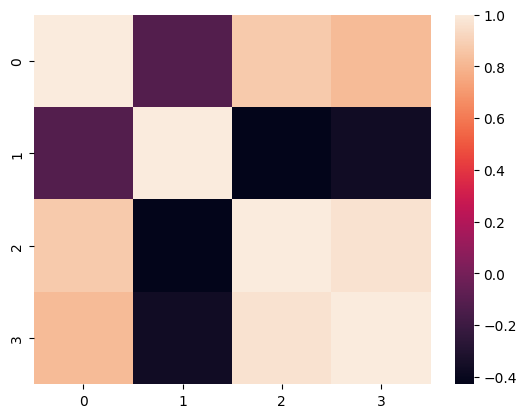

In [15]:
# Mengecek korelasi antara fitur dari data
corr = scaled_data.corr()
print(corr)
sns.heatmap(scaled_data.corr())

Penjelasan: korelasi menunjukkan seberapa kuat hubungan antar fitur (-1 sampai 1).
Heatmap memudahkan melihatnya. Fitur yang berkorelasi tinggi artinya informasinya mirip, sehingga dimensi data bisa dikurangi.

## 2. **Dimensionality Reduction with PCA**

In [16]:
# Menerapkan PCA dengan principal component sebanyak 3
pca = PCA(n_components = 3)
data_pca = pca.fit_transform(scaled_data)
data_pca = pd.DataFrame(data_pca,columns=['PC1','PC2','PC3'])
data_pca.head()

,PC1,PC2,PC3
0,-2.264703,0.480027,0.127706
1,-2.080961,-0.674134,0.234609
2,-2.364229,-0.341908,-0.044201
3,-2.299384,-0.597395,-0.091290
4,-2.389842,0.646835,-0.015738


Penjelasan: data 4 fitur diubah menjadi 3 komponen utama (PC1, PC2, PC3).

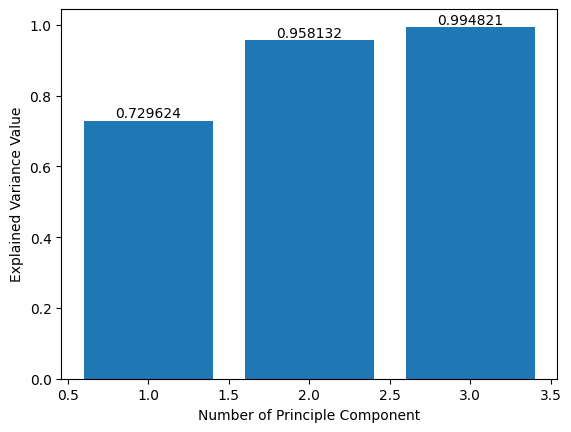

In [17]:
# Memetakan setiap nilai Explained Variance dari setiap jumlah principle component dalam grafik
list_explained_variance_pca = pca.explained_variance_ratio_.cumsum()
label_x = list(range(1, len(list_explained_variance_pca)+1))
fig, ax = plt.subplots()
bars = ax.bar(label_x, list_explained_variance_pca)
ax.bar_label(bars, label_type='edge', color='black')
ax.set_xlabel("Number of Principle Component")
ax.set_ylabel("Explained Variance Value")
plt.show()

Penjelasan: explained variance menunjukkan berapa persen informasi data yang dipertahankan.
cumsum() menjumlahkannya secara berurutan, jadi batang ke-3 adalah total informasi yang tersisa jika memakai 3 komponen.

<Axes: >

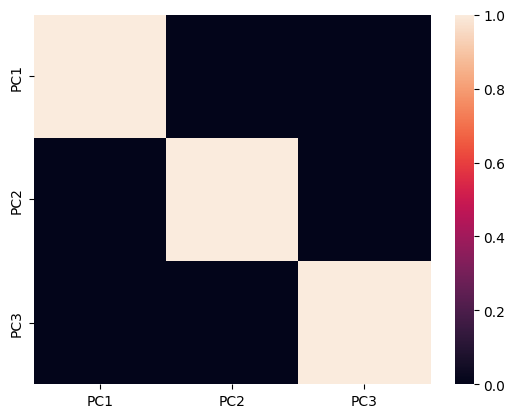

In [18]:
# Mengecek korelasi antara Principle Component, yang seharusnya memiliki nilai
# korelasi yang kecil dari setiap principle component
sns.heatmap(data_pca.corr())

Penjelasan: komponen PCA saling tegak lurus, jadi korelasi antar komponen mendekati 0 (hanya diagonal yang bernilai 1). Artinya tidak ada informasi yang tumpang tindih.

## 3. **Dimensionality Reduction with SVD**

In [19]:
# Menerapkan SVD dengan pertimbangan penurunan komponen menjadi sebanyak 3
svd = TruncatedSVD(n_components = 3)
data_svd = svd.fit_transform(scaled_data)
data_svd = pd.DataFrame(data_svd,columns=['PC1','PC2','PC3'])
data_svd.head()

,PC1,PC2,PC3
0,-2.264703,0.480027,0.127706
1,-2.080961,-0.674134,0.234609
2,-2.364229,-0.341908,-0.044201
3,-2.299384,-0.597395,-0.091290
4,-2.389842,0.646835,-0.015738


Penjelasan: TruncatedSVD mengurangi data menjadi 3 komponen, mirip PCA.
Bedanya, SVD tidak mengurangi rata-rata data terlebih dahulu (tidak melakukan centering).
Karena data sudah di-scale (rata-rata 0), hasilnya akan sangat mirip dengan PCA.

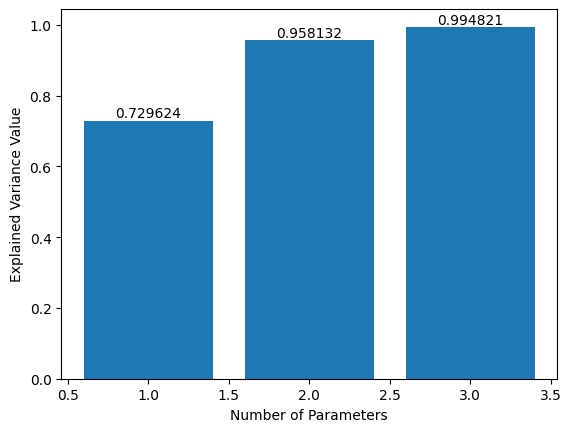

In [20]:
# Memetakan setiap nilai Explained Variance dari setiap jumlah parameter dalam grafik
list_explained_variance_svd = svd.explained_variance_ratio_.cumsum()
label_x = list(range(1, len(list_explained_variance_svd)+1))
fig, ax = plt.subplots()
bars = ax.bar(label_x, list_explained_variance_svd)
ax.bar_label(bars, label_type='edge', color='black')
ax.set_xlabel("Number of Parameters")
ax.set_ylabel("Explained Variance Value")
plt.show()

Penjelasan: sama seperti PCA, grafik ini menunjukkan total informasi yang dipertahankan oleh 1, 2, dan 3 komponen hasil SVD. Bandingkan nilainya dengan grafik PCA.

<Axes: >

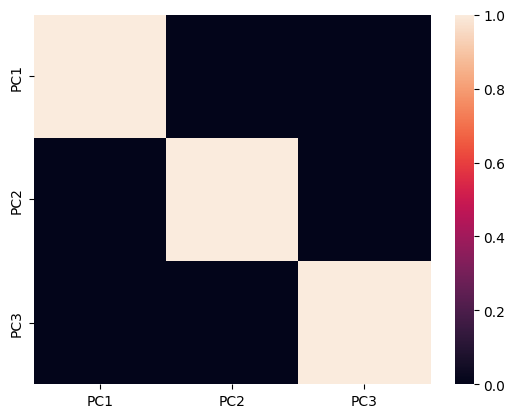

In [21]:
# Mengecek korelasi antara parameter hasil svd, yang seharusnya memiliki nilai
# korelasi yang kecil dari setiap parameter
sns.heatmap(data_svd.corr())

Penjelasan: dicek apakah komponen hasil SVD juga saling tidak berkorelasi.
Nilai di luar diagonal yang kecil berarti komponennya saling bebas.

## 4. **Data Visualization After Dimensionality Reduction**

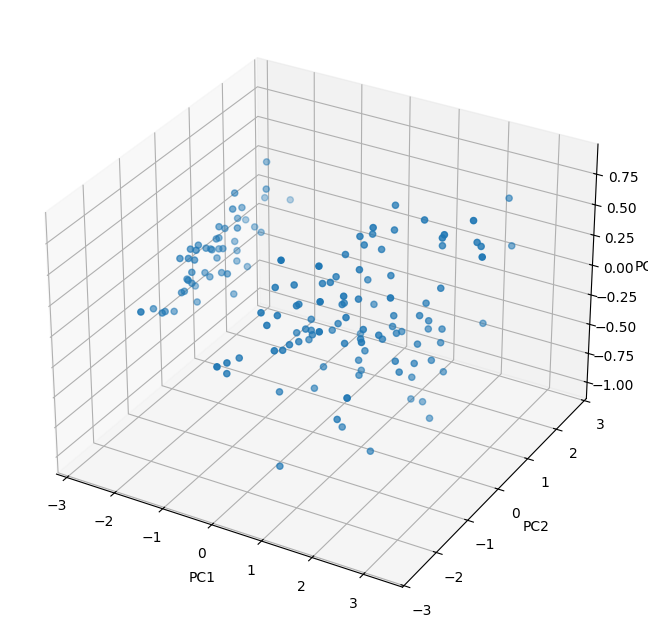

In [22]:
# Membuat visualisasi dari sebaran data dengan pertimbangan principle component
# dalam ruang 3 dimensi
fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(data_pca['PC1'], data_pca['PC2'], data_pca['PC3'])
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
plt.show()

Penjelasan: setiap titik adalah satu bunga, dengan posisi ditentukan oleh PC1, PC2, dan PC3. Dari sini kita bisa melihat apakah data membentuk kelompok (cluster) tertentu.